# 1.05 · MiBici station usage profiles: dimensionality reduction (PCA)

**Phase 1 (data preparation)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `1.04` because it reads that notebook's output.

- **Input:** `data/processed/mibici/features/station_hour_features.parquet` (notebook `1.04`) and the station nomenclature.
- **Output:** `data/processed/mibici/features/station_profiles.parquet`, each station's scores on the principal components, tracked in MLflow.

**Why.** Notebook `1.04` found that the target encoding gives no information about the roughly 100 stations opened in 2026. The [ML Canvas](../references/ml-canvas.md) therefore proposes a station *usage-profile* feature. A station's profile is the share of its trips that depart and that arrive in each of the 168 hours of the week: 336 correlated columns. PCA reduces them to a few components that describe *how* a station is used, whatever its volume.

1. Build the profiles on the training period only.
2. Why the 336 columns are redundant.
3. Choose the number of components.
4. Interpret the first three components.
5. Check whether a new station's first four weeks are enough to place it.
6. Write the scores and track the run in MLflow.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.data.trip_data import load_stations
from team2_mlops2026.features import FEATURES_DIR, FEATURES_FILE, STATION, TARGETS, TIME
from team2_mlops2026.station_profiles import (
    HOURS_PER_WEEK,
    MIN_TRIPS,
    component_scores,
    create_profiles_tracked,
    first_weeks,
    fit_pca,
    hour_of_week_profiles,
    loadings,
)

pd.set_option("display.max_columns", 50)
plots.use_style()

2026-10-24 15:03:04.320 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: /Users/xavier/code/tecmty/mlops/fase1Proyecto/MLOps_Team2


## Parameters

The PCA is fitted on the training period of `1.04` (everything before its test year), so the components contain no test information.

In [3]:
FIT_END = "2025-10"  # first month of the test period in 1.04
NEW_STATION_WEEKS = 4  # history used to place a new station
MIN_TRIPS_SHORT = 100  # minimum trips for a profile built from those weeks

## 1. Station profiles

In [4]:
features = pd.read_parquet(FEATURES_DIR / FEATURES_FILE, columns=[STATION, TIME, *TARGETS])
stations = load_stations().set_index("id")

profiles = hour_of_week_profiles(features, end=FIT_END)
in_fit = features.loc[features[TIME] < FIT_END, STATION].nunique()
print(f"Profiles: {profiles.shape[0]} stations x {profiles.shape[1]} columns "
      f"({in_fit - len(profiles)} of {in_fit} stations in the period have < {MIN_TRIPS} trips)")
profiles.iloc[:3, 6:12]

Profiles: 371 stations x 336 columns (13 of 384 stations in the period have < 500 trips)


,departures_mon_06,departures_mon_07,departures_mon_08,departures_mon_09,departures_mon_10,departures_mon_11
station_id,,,,,,
2,0.002552,0.005615,0.007687,0.006688,0.003876,0.003486
3,0.002405,0.003635,0.006867,0.004255,0.003885,0.003101
4,0.000740,0.002343,0.004115,0.003553,0.003360,0.003337


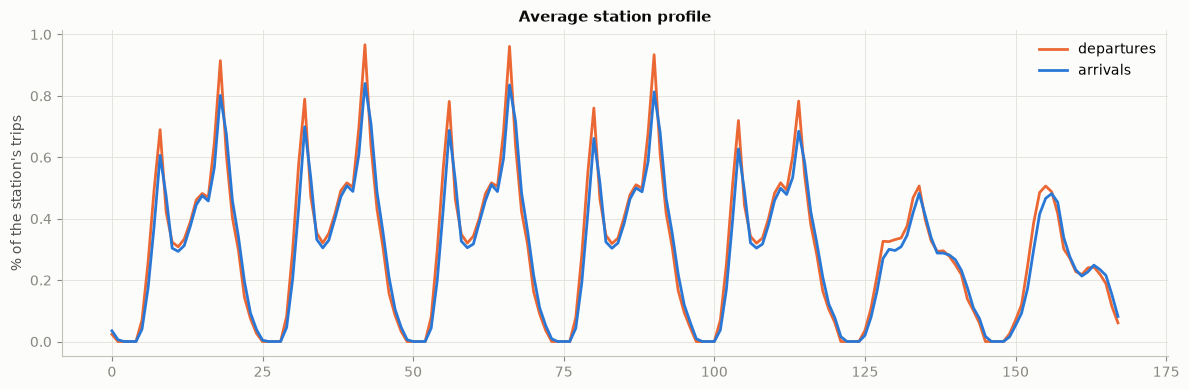

In [5]:
def by_hour_of_week(values: pd.Series) -> pd.DataFrame:
    """336 profile values -> 168 rows (hour of the week) x departures / arrivals."""
    return pd.DataFrame(
        {t: values.filter(like=f"{t}_").to_numpy() for t in TARGETS},
        index=pd.RangeIndex(HOURS_PER_WEEK, name="hour of the week (0 = Monday 00:00)"),
    )


plots.plot_lines(by_hour_of_week(profiles.mean()) * 100, "Average station profile", "% of the station's trips");

**Result → action.** 371 of the 384 stations active in the training period (2023-01 to 2025-09) have at least 500 trips and get a profile. The other 13 are left out, because a few trips do not describe a pattern. The average station follows the weekday commuter shape (peaks at 8:00 and 18:00, with the evening one higher) and has a flatter midday bump on weekends. Departures and arrivals look alike on average, so what tells stations apart is how each one deviates from this shape, and that deviation is what PCA picks up.

→ Each station is described by 336 shares that sum to 1, independent of its volume.

## 2. Why reduce: the 336 columns are redundant

In [6]:
corr = profiles.corr().to_numpy()
pairs = corr[np.triu_indices_from(corr, k=1)]
adjacent = [
    np.corrcoef(profiles.iloc[:, i], profiles.iloc[:, i + 1])[0, 1]
    for i in range(profiles.shape[1] - 1)
    if (i + 1) % HOURS_PER_WEEK and profiles.iloc[:, i].std() and profiles.iloc[:, i + 1].std()
]
same_hour = [
    np.corrcoef(profiles[f"{t}_tue_{h:02d}"], profiles[f"{t}_wed_{h:02d}"])[0, 1]
    for t in TARGETS
    for h in range(6, 23)
]
pd.Series(
    {
        "median |r|, all column pairs": np.nanmedian(np.abs(pairs)),
        "median r, consecutive hours": np.nanmedian(adjacent),
        "median r, same hour Tue vs Wed (06-22 h)": np.median(same_hour),
        "columns with no variance (hours without trips)": int((profiles.std() == 0).sum()),
    }
).round(3).to_frame("value")

,value
"median |r|, all column pairs",0.108
"median r, consecutive hours",0.521
"median r, same hour Tue vs Wed (06-22 h)",0.905
columns with no variance (hours without trips),15.000


**Result → action.** Most pairs of columns are unrelated (median |r| 0.11), but the dependence that does exist is strong and structured. Consecutive hours move together (median r 0.52), and the same hour on Tuesday and on Wednesday is almost the same variable (median r 0.91 from 06:00 to 22:00). 15 night columns have no variance at all, because no station ever has a trip in those hours.

→ The profile has far fewer independent directions than columns, so PCA can summarise it. The zero-variance columns are also why the shares are not standardized (next section).

## 3. How many components

The shares are centred but **not scaled**. They are already on one scale, and standardizing would divide the almost-empty night hours by a tiny deviation, so their noise would weigh as much as the rush hours. Some night columns have no variance at all.

In [7]:
full = fit_pca(profiles, None)
ratio = pd.Series(full.explained_variance_ratio_, index=range(1, len(full.explained_variance_ratio_) + 1))
cumulative = ratio.cumsum()
display(pd.Series({f"{t:.0%}": int((cumulative < t).sum() + 1) for t in (0.5, 0.8, 0.9, 0.95)},
                  name="components needed").to_frame().T)
ratio.head(6).round(3).to_frame("explained variance ratio").T

,50%,80%,90%,95%
components needed,3,12,26,51


,1,2,3,4,5,6
explained variance ratio,0.281,0.172,0.109,0.059,0.046,0.03


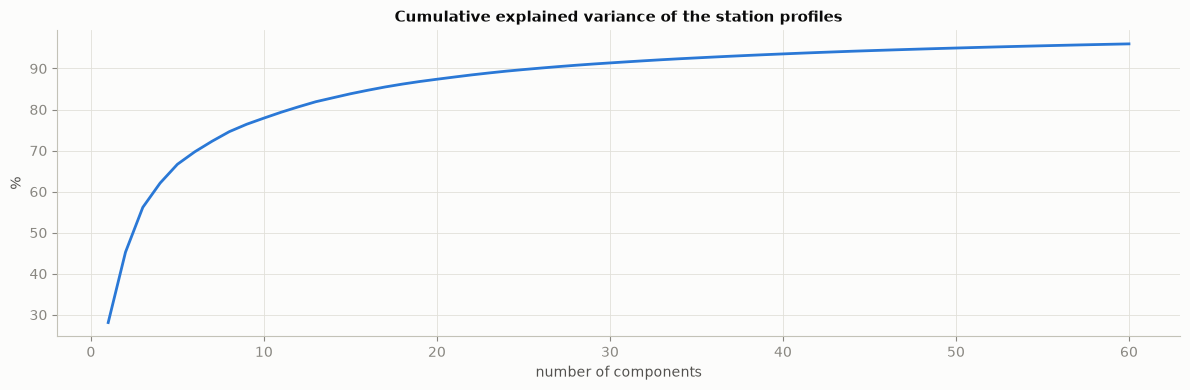

In [8]:
plots.plot_lines(
    (cumulative.head(60) * 100).to_frame("cumulative explained variance"),
    "Cumulative explained variance of the station profiles", "%", xlabel="number of components",
);

**Result → action.** The first component explains 28% of the variance, the second 17% and the third 11%; together they carry 56%. Reaching 80% takes 12 components, 90% takes 26 and 95% takes 51. After the fifth component each one adds 3% or less, and the tail is mostly the noise of individual hours.

→ The stored scores keep the **26 components that explain 90%**, which reduces the 336 columns about 13-fold and lets later models choose how many to use. The first three are interpreted below.

## 4. What the first components mean

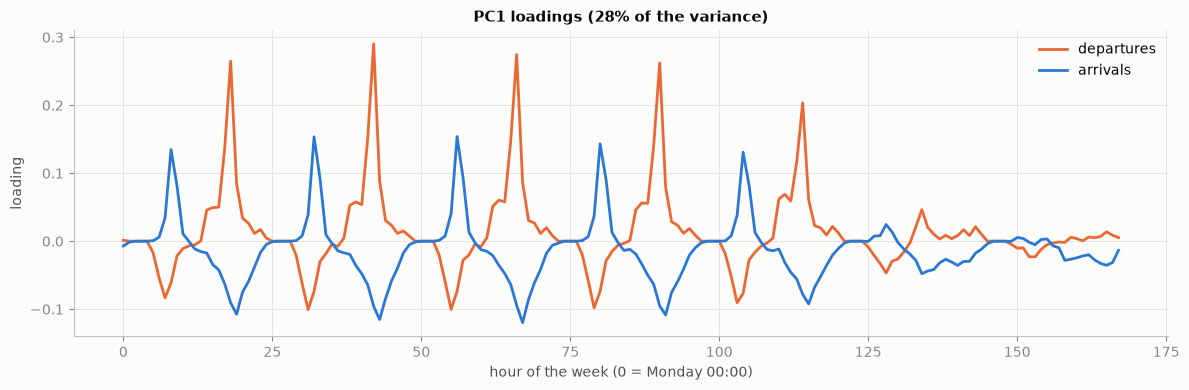

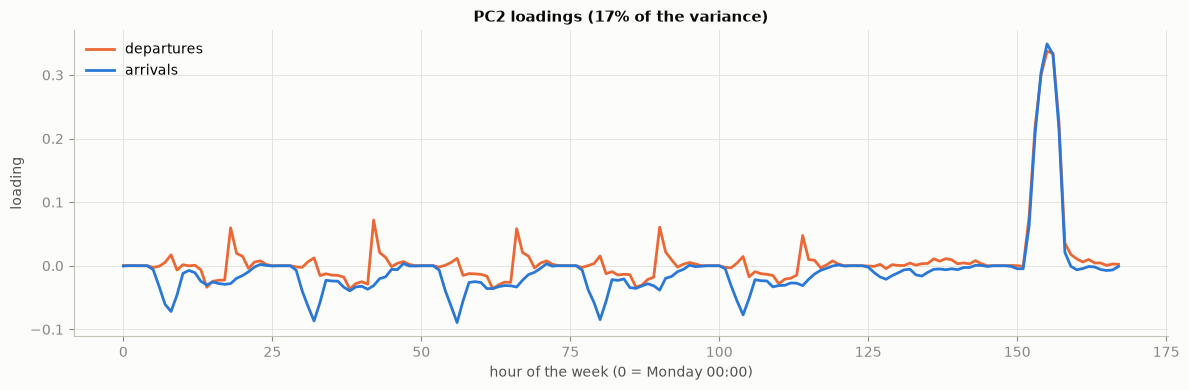

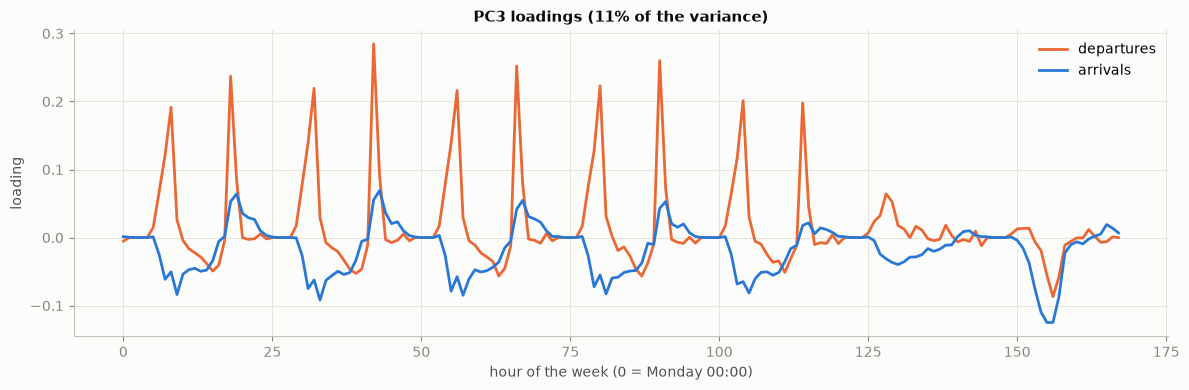

In [9]:
pca = fit_pca(profiles)  # 90% of the variance
scores = component_scores(pca, profiles)
weights = loadings(pca, 3)
for i, pc in enumerate(weights, start=1):
    plots.plot_lines(
        by_hour_of_week(weights[pc]), f"{pc.upper()} loadings ({pca.explained_variance_ratio_[i - 1]:.0%} of the variance)",
        "loading", xlabel="hour of the week (0 = Monday 00:00)",
    )

In [10]:
weekday_am = profiles.columns.str.contains("_(?:mon|tue|wed|thu|fri)_(?:06|07|08|09|10)$")
traits = pd.DataFrame(
    {
        "departure share": profiles.filter(like="departures_").sum(axis=1),
        "weekend share": profiles.loc[:, profiles.columns.str.contains("_(?:sat|sun)_")].sum(axis=1),
        "weekday 06-10 arrivals - departures": (
            profiles.loc[:, weekday_am & profiles.columns.str.startswith("arrivals")].sum(axis=1)
            - profiles.loc[:, weekday_am & profiles.columns.str.startswith("departures")].sum(axis=1)
        ),
    }
)
traits.apply(lambda trait: scores[["pc1", "pc2", "pc3"]].corrwith(trait)).T.round(2)

,pc1,pc2,pc3
departure share,0.57,0.29,0.45
weekend share,-0.25,0.85,-0.20
weekday 06-10 arrivals - departures,0.70,-0.24,-0.58


In [11]:
extremes = {
    (pc, side): [stations["name"].get(i, f"id {i}") for i in ids]
    for pc in ("pc1", "pc2", "pc3")
    for side, ids in (("lowest", scores[pc].nsmallest(3).index), ("highest", scores[pc].nlargest(3).index))
}
with pd.option_context("display.max_colwidth", 50):
    display(pd.DataFrame.from_dict(extremes, orient="index", columns=["1st", "2nd", "3rd"]))

,1st,2nd,3rd
"(pc1, lowest)",(GDL-243)Av. De los Maestros / C. Mil Cumbres,(GDL-242) C. Sevilla / Av. de los Maestros,(GDL-233) S .Juan de Ulúa /Andrés Q.R.
"(pc1, highest)",ex-(ZPN-063) C. San Felipe Neri / Av. Guadalu,(ZPN-040) C. Santa María / C. Árbol,(GDL-118) C. Antonio de León / C. Garibaldi
"(pc2, lowest)",(GDL-180) C. Montes Pirineos/Salvador Quevedo,(GDL-252) C. Calpulalpan / C. Independencia,(GDL-202) C. Magisterio / C. Durango
"(pc2, highest)",(GDL-262) Av. Gigantes / C. Aquiles Serdán,(GDL-154) C. Capuchinas / Av. Las Rosas,(GDL-254) Porfirio Díaz/Francisco Javier Mina
"(pc3, lowest)",(GDL-262) Av. Gigantes / C. Aquiles Serdán,(ZPN-018) Av. Laureles / Blvrd. Panamericano,(GDL-046) C. Emerson / Av. Vallarta
"(pc3, highest)",ex-(ZPN-063) C. San Felipe Neri / Av. Guadalu,(ZPN-104) Av. D / C. 9,(ZPN-024) C. Francisco Sarabia / Av. Laureles


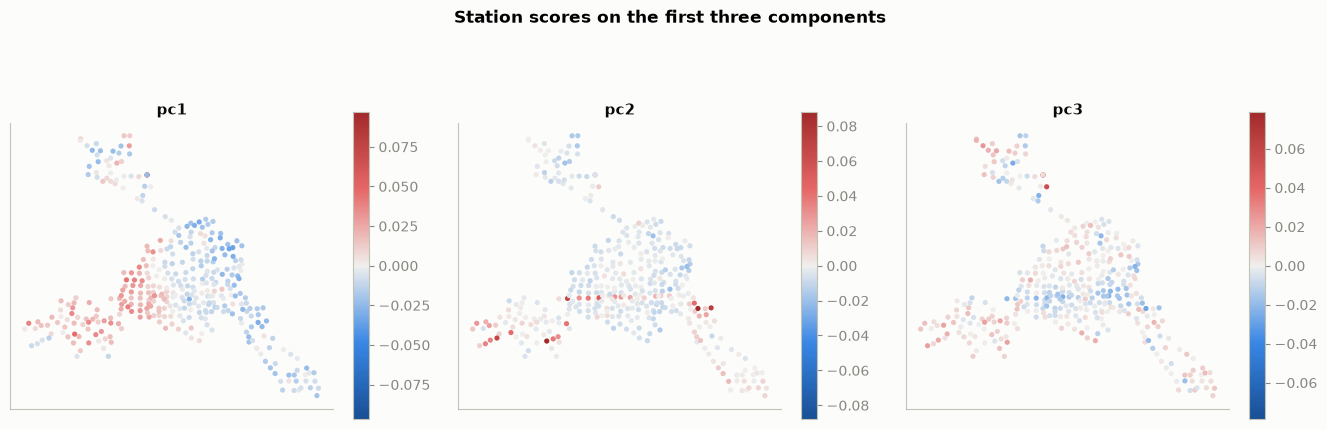

In [12]:
located = scores.join(stations[["latitude", "longitude"]], how="inner")
plots.plot_maps(located["longitude"], located["latitude"], located[["pc1", "pc2", "pc3"]],
                "Station scores on the first three components");

**Result → action.** The first three components are distinct usage types:
- **PC1 (28%): destination vs origin of the weekday commute.**
  - Positive loadings: weekday arrivals around 8:00 and departures around 18:00, so people come to the station in the morning and leave in the evening (work and study areas). Negative loadings: the reverse, typical of residential stations.
  - The score correlates 0.70 with a station's weekday morning arrivals minus departures.
  - Avenida de los Maestros (GDL-243, GDL-242) is at the residential end. On the map, high scores cluster in the west-central part of the network, and the eastern and outer stations score low.
- **PC2 (17%): weekend leisure vs weekday commuting.**
  - Positive loadings: Sunday 10:00-13:00 in both directions. Negative loadings: weekday morning arrivals.
  - The score correlates 0.85 with the share of weekend trips.
  - The highest stations (Av. Gigantes GDL-262, Las Rosas GDL-154, Porfirio Díaz GDL-254, Av. Vallarta / Los Arcos GDL-127) line up along a few corridors on the map. This is consistent with the Sunday open-streets route (Vía RecreActiva).
- **PC3 (11%): stations that mostly send bikes out.**
  - Positive loadings: weekday departures at *both* peaks. Negative loadings: arrivals, on weekday mornings and on Sundays.
  - The score correlates 0.45 with the departure share and −0.58 with morning net arrivals.
  - Across stations, departures range from 23% to 79% of a station's trips. High-PC3 stations tend to lose bikes over the week, so they are the ones a rebalancing plan has to restock.

→ The components describe *how* each station is used: commute direction, leisure and net imbalance. The station id and its target encoding cannot provide this, and it applies to any station with some history.

## 5. Is a short history enough to place a new station?

A new station has no profile until it has a history. Two checks:

1. **Stability.** For the stations already profiled, build a profile from only the last 4 weeks before `FIT_END`, project it with the same PCA and compare it with the full-period scores.
2. **New stations.** Project the first 4 weeks of every station that opened after `FIT_END`.

In [13]:
window = features[(features[TIME] >= pd.Timestamp(FIT_END) - pd.Timedelta(weeks=NEW_STATION_WEEKS))
                  & (features[TIME] < FIT_END)]
short = hour_of_week_profiles(window, min_trips=MIN_TRIPS_SHORT)
common = short.index.intersection(profiles.index)
short_scores = component_scores(pca, short.loc[common])
pd.Series(
    {pc: np.corrcoef(scores.loc[common, pc], short_scores[pc])[0, 1] for pc in ["pc1", "pc2", "pc3", "pc4", "pc5"]},
    name=f"r (full period vs last {NEW_STATION_WEEKS} weeks, {len(common)} stations)",
).round(3).to_frame().T

,pc1,pc2,pc3,pc4,pc5
"r (full period vs last 4 weeks, 367 stations)",0.918,0.951,0.775,0.77,0.764


In [14]:
opened = features.groupby(STATION)[TIME].min()
new_ids = opened[opened >= FIT_END].index
new_rows = first_weeks(features[features[STATION].isin(new_ids)], NEW_STATION_WEEKS)
trips = new_rows.groupby(STATION)[list(TARGETS)].sum().sum(axis=1)
new_scores = component_scores(pca, hour_of_week_profiles(new_rows, min_trips=MIN_TRIPS_SHORT))
print(f"New stations: {len(new_ids)}; with >= {MIN_TRIPS_SHORT} trips in their first {NEW_STATION_WEEKS} weeks: "
      f"{len(new_scores)} (median {trips.median():.0f} trips)")
pd.concat(
    {"existing": scores[["pc1", "pc2", "pc3"]].agg(["mean", "std"]),
     "new (first 4 weeks)": new_scores[["pc1", "pc2", "pc3"]].agg(["mean", "std"])}
).round(4)

New stations: 102; with >= 100 trips in their first 4 weeks: 99 (median 301 trips)


pc1     pc2     pc3
existing            mean  0.0000 -0.0000 -0.0000
                    std   0.0171  0.0134  0.0107
new (first 4 weeks) mean -0.0052  0.0103 -0.0022
                    std   0.0188  0.0198  0.0106

**Result → action.** - **Stability:** with only the last 4 weeks, PC1 and PC2 reproduce the full-period scores (r = 0.92 and 0.95). PC3 to PC5 are noisier (r ≈ 0.77).
- **New stations:** 99 of the 102 stations opened after `FIT_END` have at least 100 trips in their first 4 weeks (median 301) and can be placed.
  - On PC1 and PC3 they spread like the existing stations.
  - On PC2 they lean towards weekend use (mean +0.010, about 0.8 standard deviations of the existing stations) and spread more (0.020 vs 0.013).
  - Their first weeks fall between May and August 2026, which includes the summer holidays when commuting drops, so part of that lean may be seasonal rather than a property of the stations.

→ After 4 weeks, a new station's PC1 and PC2 scores are reliable enough to stand in for the station encoding it lacks. They should be refreshed as its history grows.

## 6. Write the station scores and track the run

`create_profiles_tracked()` repeats the fit with the same settings, writes every profiled station's scores on the components that explain 90% of the variance, and logs an MLflow run (`fit-station-profiles`) with:
- the station-hour features as input and the scores as output, each with a digest
- the profile definition and PCA settings as params
- the explained variance as metrics, and each component's share as an artifact

In [15]:
summary = create_profiles_tracked(fit_end=FIT_END)
print(f"MLflow run {summary['mlflow_run_id']} in experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
print(f"{summary['stations']} stations x {summary['components']} components "
      f"({summary['explained_variance']:.1%} of the variance) -> {summary['path'].split('data/')[-1]}")
assert np.allclose(pd.read_parquet(summary["path"]).set_index(STATION), scores)  # same fit as above

/Users/xavier/code/tecmty/mlops/fase1Proyecto/MLOps_Team2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-24 15:03:14.201 | SUCCESS  | team2_mlops2026.station_profiles:create_profiles:163 - Station profiles: 371 stations, 26 components explain 90.1% of the variance
🏃 View run fit-station-profiles at: http://127.0.0.1:5001/#/experiments/1/runs/c254b1aa526c47debf4e904a27383816
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
MLflow run c254b1aa526c47debf4e904a27383816 in experiment 'mibici' (http://127.0.0.1:5001)
371 stations x 26 components (90.1% of the variance) -> processed/mibici/features/station_profiles.parquet


## Findings and next steps

**Output**
- `data/processed/mibici/features/station_profiles.parquet` holds 371 stations × 26 components that explain 90.1% of the profile variance. The PCA is fitted on 2023-01 to 2025-09 only, so it contains no test information.
- Every fit is an MLflow run (`fit-station-profiles`). Its input digest is the station-hour feature table, which extends the tracked lineage to cleaning → features → profiles. `python -m team2_mlops2026.station_profiles` reproduces it in a few seconds.

**Dimensionality reduction**
- Each station's 336 hour-of-week shares are reduced to 26 components, about a 13-fold reduction.
- The first three components carry 56% of the variance and are interpretable: commute direction (destination vs origin), weekend leisure, and net imbalance (stations that send bikes out).
- The shares are centred but not scaled, because 15 night columns have no variance and scaling would turn noise into signal.

**Implications for the next stages**
- *Modelling (phase 2):* join the scores on `station_id` as station features, alongside the target encoding of `1.04` or instead of it. A new station gets scores from its first 4 weeks (`first_weeks` and `component_scores` with the fitted PCA, no refit). The PCA is refitted whenever the training window moves.
- *Rebalancing:* PC3 directly flags the stations that need restocking, which is the decision in the ML Canvas.
- *Limitation:* each profile summarises a whole period, so seasonal changes such as summer holidays or new stations that are still ramping up can shift the scores. Monitoring should track them over time.